# DX 799 mod C2 Deb Halder 2026 Fall - 3rd Dataset- New

### Phishing Email dataset 3rd dataset (new dataset and not part of my dataset in DX699 C2)

- This is a new dataset that I am adding (link: https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset/data) and was not part of the original datset. This is  one of the best dataset that I havve seen on Kaggle and has about 82486 records from different sources  and different types of fields. It also has a one file which has all the data from the six other data files
- In the previous spam/phishing detection data set I had used NLTK library to do  identify stopwords , and  created setof features based on patterns of words noticed. 
- In this notebook I will compare the previous methods perfromance and comapre with generating pattern based on TF-IDF score of words and use with 5000 bigrams . This is a methd which I learned during advanced machine larning class  and I am expecting the perfromanc of the classification will be better.
- Though the ulitmate intent is classification but I wll use regression with three different algorithms for linear regression with Lasso , Ridge and Elastic net regularization and compare performance and create confusion matrix to evaluate performance of it as classification engine. We will use 0.5  as the probabaility threshold so anything above 0.5 is considered 1 and any value less than equa to 0.5 will be marked as zero. We will also compare the RMAC and AUC besides confusion matrix to understnad perfromance. I will also try to understnad the computation time for each . Since this is a big data set so compute time difference will be quickly identified .
- I will continue to make this better through this and then next Capstone mod C2  so as I can evolve into the final project

#### Objectve- Evaluating linear regression models across custom 9 static count features and TF-IDF text n-grams on a scaled dataset of ~82,000 emails (16,101 test samples) leads to a clear operational winner:

TF-IDF + Ridge delivers the single best classification performance with an F1 score of 0.9734, Precision of 0.9691, Recall of 0.9777, and ROC AUC of 0.9960 at a decision threshold of 0.5. It completes model fitting in 82.51 seconds—over 10 times faster than Elastic Net (860.33 seconds) while achieving superior accuracy.

Secondary Edge Pick (TF-IDF + Lasso): Performs aggressive feature selection by pruning 78.4% of features (reducing the weight array from 3,000 down to 648 active non-zero coefficients). It maintains a strong 0.9644 F1 score and fits in 130.55 seconds, making it optimal for memory-constrained edge deployments.

Static Count Features Are Unviable Alone: While expanding the dataset to ~82,000 samples boosted static count ROC AUC from baseline (~0.51) to ~0.775, at a 0.5 decision threshold these features generate an unacceptable false alarm rate—misclassifying 59% to 65% of legitimate emails as phishing.

##### What Works Well (TF-IDF Features)

* **High Predictive Accuracy:** TF-IDF text representations achieve near-perfect classification across all regularizations, reaching an ROC AUC between **0.9930 and 0.9960** and F1 scores between **0.9644 and 0.9734** on the 16,101-sample test set.
* **Low False Positive Count:** **TF-IDF Ridge** yields the top performance overall, producing only **258 False Positives** and **185 False Negatives** (F1: **0.9734**, Precision: **0.9691**, Recall: **0.9777**) with an **82.51-second** fit time across all 3,000 features.
* **Effective Sparsity:** **TF-IDF Lasso** successfully eliminates **78.4% of features**, pruning the parameter set from 3,000 down to **648 active weights** while maintaining an F1 score of **0.9644** in **130.55 seconds**.

##### What Performs Poorly (9 Static Count Features)

* **Severe False Positive Bias:** At a 0.5 decision threshold, count features incorrectly classify **59.0% to 65.7% of legitimate emails as phishing** (**4,613 to 5,136 False Positives** out of 7,813 legitimate test emails).
* **Limited Predictive Signal:** Count-based models cap at an F1 score of **0.7258** (Ridge) and an ROC AUC of **0.7759** (Lasso), failing to capture sufficient semantic context.
* **Feature Redundancy:** Lasso drops 5 of the 9 custom count features (retaining **4**), while Ridge and Elastic Net retain **6**, indicating that at least 3 static count features carry no distinct predictive value.

##### Execution Speed & Model Complexity

* **Fastest Fit:** Static count models train in **6.89 to 18.21 seconds** but yield high error rates.
* **Slowest Fit:** **TF-IDF Elastic Net** requires **860.33 seconds** to fit, retaining 2,152 features and achieving a **0.9719 F1 score**, which does not outperform the faster TF-IDF Ridge model.

#### Execution Flow of Phishing Email Classification Pipeline

1. **Load and label:** read the dataset and standardize `text_combined` and binary `label` columns.
2. **Clean once:** `prepare_email_corpus()` keeps the original email in `text` and stores `clean_email_text()` results in `word_text`. This removes HTML, script/style contents, URLs, addresses, and non-word characters; stopwords remain at this stage.
3. **Filter and group:** remove unusable rows, set aside conflicting labels, and deduplicate whitespace-normalized text. Hash normalized word sequences into `group_id`; matching keys stay together during splitting. This rule does not detect every paraphrase or near-duplicate.
4. **Extract nine counts:** `extract_count_features(corpus)` reads the stored `word_text` for word and keyword counts. It uses raw `text` for HTTP/HTTPS counts and visible text with punctuation for sentence counts. Protected keywords and negations survive stopword filtering; phrase positions prevent filtering from creating false matches. The filtered word sequence is stored in `clean_text`.
5. **Split:** `split_email_corpus()` creates a grouped holdout and training-only cross-validation folds. Labels and group identifiers remain outside the predictors.
6. **Fit:** fit TF-IDF and any learned scaling on each training fold inside the model pipeline. Transform validation and holdout rows using the fitted preprocessing. The notebook configuration selects the text column, feature cap, and model families.
7. **Evaluate:** select configurations using training cross-validation, then report the selected models on the holdout. Reuse stored predictions and scores for tables and plots.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time       # to calculate execution time
import hashlib
import re

import shutil # will help with file management copy and delete to remove files and folders as needed
import kagglehub

from pathlib import Path
from IPython.display import display
from tempfile import TemporaryDirectory
from joblib import Memory
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from collections import Counter
from html.parser import HTMLParser
import html
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from joblib import Memory

In [ ]:
RANDOM_STATE = 42  # Set a random state for reproducibility

# Create the destination directory if it does not exist
destination_dir = Path("./dataset/phishing_email_dataset")
destination_dir.mkdir(parents=True, exist_ok=True)

# Download the latest Kaggle dataset
download_path = Path(
    kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")
)

print("KaggleHub download directory:")
print(download_path)

# Find downloaded files
downloaded_files = [
    file_path
    for file_path in download_path.rglob("*")
    if file_path.is_file()
]

if not downloaded_files:
    raise FileNotFoundError(
        f"No files found in the Kaggle download directory: {download_path}"
    )

# Copy downloaded files into the project directory
for source_file in downloaded_files:
    destination_file = destination_dir / source_file.name
    shutil.copy2(source_file, destination_file)
    print(f"Saved: {destination_file}")

# Find the downloaded CSV file
csv_files = sorted(destination_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {destination_dir}"
    )

print("\nCSV files found:")
for csv_file in csv_files:
    print(csv_file.name)

print("\nLoaded phishing website dataset:")

# Delete only this dataset's KaggleHub cache directory
if download_path.exists() and download_path.is_dir():
    shutil.rmtree(download_path)
    print("\nDeleted KaggleHub cache directory:")
    print(download_path)
else:
    print("\nKaggleHub cache directory was not found:")
    print(download_path)

Resuming download from 79691776 bytes (1172778 bytes left)...
Resuming download to /Users/debasishhalder/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/1.archive (79691776/80864554) bytes left.


100%|██████████| 77.1M/77.1M [00:00<00:00, 4.48MB/s]

Extracting files...


KaggleHub download directory:
/Users/debasishhalder/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/versions/1
Saved: dataset/phishing_email_dataset/Nigerian_Fraud.csv
Saved: dataset/phishing_email_dataset/Ling.csv
Saved: dataset/phishing_email_dataset/Nazario.csv
Saved: dataset/phishing_email_dataset/SpamAssasin.csv
Saved: dataset/phishing_email_dataset/CEAS_08.csv
Saved: dataset/phishing_email_dataset/phishing_email.csv
Saved: dataset/phishing_email_dataset/Enron.csv

CSV files found:
CEAS_08.csv
Enron.csv
Ling.csv
Nazario.csv
Nigerian_Fraud.csv
SpamAssasin.csv
phishing_email.csv

Loaded phishing website dataset:

Deleted KaggleHub cache directory:
/Users/debasishhalder/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/versions/1


In [ ]:
import re

# Folder containing the datasets
data_dir = Path("./dataset/phishing_email_dataset")

if not data_dir.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {data_dir.resolve()}"
    )

# Find all CSV files in the folder
csv_files = sorted(data_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {data_dir.resolve()}"
    )

loaded_dataframes = {}

for file_path in csv_files:
    # Convert the filename into a valid DataFrame variable name.
    # Example: Enron.csv -> df_enron
    safe_name = re.sub(
        r"\W+",
        "_",
        file_path.stem.lower(),
    ).strip("_")

    dataframe_name = f"df_{safe_name}"

    dataframe = pd.read_csv(file_path)

    # Create the requested DataFrame variable dynamically
    globals()[dataframe_name] = dataframe

    # Also keep all DataFrames in a dictionary for reliable iteration
    loaded_dataframes[dataframe_name] = dataframe

    print(
        f"{dataframe_name} loaded from {file_path} "
        f"with shape {dataframe.shape}"
    )

df_ceas_08 loaded from dataset/phishing_email_dataset/CEAS_08.csv with shape (39154, 7)
df_enron loaded from dataset/phishing_email_dataset/Enron.csv with shape (29767, 3)
df_ling loaded from dataset/phishing_email_dataset/Ling.csv with shape (2859, 3)
df_nazario loaded from dataset/phishing_email_dataset/Nazario.csv with shape (1565, 7)
df_nigerian_fraud loaded from dataset/phishing_email_dataset/Nigerian_Fraud.csv with shape (3332, 7)
df_spamassasin loaded from dataset/phishing_email_dataset/SpamAssasin.csv with shape (5809, 7)
df_phishing_email loaded from dataset/phishing_email_dataset/phishing_email.csv with shape (82486, 2)


In [ ]:
# sample 3 rows from each label group (0 and 1) for each DataFrame

sampled_dfs = {}

for dataframe_name, dataframe in loaded_dataframes.items():
    if "label" not in dataframe.columns:
        print(f"{dataframe_name}: skipped — no label column.")
        continue

    sampled_groups = []

    print("=" * 80)
    print(f"Dataset: {dataframe_name}")

    for label_value in [0, 1]:
        label_group = dataframe.loc[
            dataframe["label"] == label_value
        ]

        # Print nothing for this label if no matching rows exist.
        if label_group.empty:
            continue

        # Fresh random selection each execution, without replacement.
        selected_rows = label_group.sample(
            n=min(3, len(label_group)),
            replace=False,
        )

        print(
            f"\nLabel: {label_value}"
            f" | Available: {len(label_group):,}"
            f" | Displaying: {len(selected_rows)}"
        )

        display(selected_rows)
        sampled_groups.append(selected_rows)

    # Handle DataFrames with no matching rows without a concat error.
    sampled_dfs[dataframe_name] = (
        pd.concat(sampled_groups, ignore_index=True)
        if sampled_groups
        else dataframe.iloc[0:0].copy()
    )

Dataset: df_ceas_08

Label: 0 | Available: 17,312 | Displaying: 3


,sender,receiver,date,subject,body,label,urls
30429,Rick Delaney <hfvo@bort.ca>,Sean O'Rourke <rwqjl@cs.ucla.edu>,"Thu, 07 Aug 2008 16:21:16 -0500",Re: possible to avoid slowdown on large m//g?,"On Nov 10 2007, Sean O'Rourke wrote:\n> \n> I ...",0,0
14367,Tejovathi P <ssdrjyvkl.o@gmail.com>,"kpitck-aew45@python.org, zi9rpy-fcecq@lists.so...","Wed, 06 Aug 2008 21:56:45 +0530",[Py2exe-users] Regarding Threads and locals(),"Hi all,\n\nI have a GUI applicaion(along with ...",0,0
3184,"""CafePress.com"" <luyamh@info.cafepress.com>",user6@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 21:45:34 -0500",Shirts and designs as timeless as the 80s,The web version of this email is the ideal way...,0,1



Label: 1 | Available: 21,842 | Displaying: 3


,sender,receiver,date,subject,body,label,urls
36279,Raul Krause <dwwebnm@webn.com>,user2.12@gvc.ceas-challenge.cc,"Fri, 08 Aug 2008 13:52:28 +0400",Change your sex life with PowerEnlarge!,\n\n\n\n\n\nPermanent results are one of the m...,1,0
472,Daily Top 10 <ecomptom_1964@loadtestasia.com>,user7-ext4@gvc.ceas-challenge.cc,"Wed, 06 Aug 2008 01:57:00 +0200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
16405,Look Pale? Visit Us! <pshelp@arwroof.com>,user2.13@gvc.ceas-challenge.cc,"Wed, 06 Aug 2008 21:41:59 +0200",The Most Trustworthy Online Drugstore,Canadian Healthcare purchases medications from...,1,1


Dataset: df_enron

Label: 0 | Available: 15,791 | Displaying: 3


...

,sender,receiver,date,subject,body,label,urls
4792,"""Marketing Manager"" <Emailcenter@cmmail.com>",<yyyy@netnoteinc.com>,"Sat, 11 May 2002 13:20:50 +0800",Grow Your Business,Dear friend You are receiving this email becau...,1,1
5297,TellYourSuccessStory <make_money299009@hotmail...,NaN,"Sun, 21 Jul 2002 16:33:57 -0400",You have nothing to loose anlt to gain-Get 220...,\n\n\n\n![](http://members.aol.com/musworld/st...,1,1
5776,"""Free Software"" <rjiohm4027@Flashmail.com>","<cjohnsto@nstar.net>, <jlloyd@shorenet.net>, <...","Thu, 08 Aug 2002 10:13:56 -1600",Web Pages Load 300% Faster without cable or DSL,Web Pages Lo= ad 300% Faster! Named Online Sof...,1,1


Dataset: df_phishing_email

Label: 0 | Available: 39,595 | Displaying: 3


,text_combined,label
33184,nita chaudhary moveonorg political action lmid...,0
32088,minority languages contex diversity standardis...,0
11969,multimedia harvard cases ken jeff louise pleas...,0



Label: 1 | Available: 42,891 | Displaying: 3


,text_combined,label
51437,provan help men even menopausal women httpwwwf...,1
82160,monkeyorgno_replymonkeyorg date subject web ac...,1
57636,marietta allred mariettaukbuildercom afford bu...,1


In [ ]:
label_counts_by_dataframe = []

for dataframe_name, dataframe in loaded_dataframes.items():
    if "label" not in dataframe.columns:
        label_counts_by_dataframe.append({
            "dataframe": dataframe_name,
            "label": "No label column",
            "label_dtype": "Not available",
            "records": len(dataframe),
        })
        continue

    label_dtype = str(dataframe["label"].dtype)

    counts = (
        dataframe["label"]
        .value_counts(dropna=False)
        .sort_index()
    )

    for label_value, record_count in counts.items():
        label_counts_by_dataframe.append({
            "dataframe": dataframe_name,
            "label": label_value,
            "label_dtype": label_dtype,
            "records": record_count,
        })

label_counts_df = pd.DataFrame(
    label_counts_by_dataframe
)

display(
    label_counts_df.sort_values(
        ["dataframe", "label"],
        na_position="last",
    ).reset_index(drop=True)
)

,dataframe,label,label_dtype,records
0,df_ceas_08,0,int64,17312
1,df_ceas_08,1,int64,21842
2,df_enron,0,int64,15791
3,df_enron,1,int64,13976
4,df_ling,0,int64,2401
5,df_ling,1,int64,458
6,df_nazario,1,int64,1565
7,df_nigerian_fraud,1,int64,3332
8,df_phishing_email,0,int64,39595
9,df_phishing_email,1,int64,42891


#### We see the information on the dataset page says this dataset file **phishing_email.csv** has all the data from other file so its combined ie total 82486 records and the data is very near balanced dataset approx 39000: 42000 in two of the labels. 

- So we will only use df_phishing_email as our dataframe  and base all subsequent activities on this dataset and drop others


#### We will not do univariate analysis as we see it s a simple dataset , it has mail text(i.e compined text and Label which is int dtype and nearly balanced). 

In [ ]:
df_combined = loaded_dataframes.get("df_phishing_email", pd.DataFrame())

In [ ]:
print(f"Combined dataset columns: {df_combined.columns}" )
df_combined.shape

Combined dataset columns: Index(['text_combined', 'label'], dtype='object')


(82486, 2)

In [ ]:
# Remove rows with missing or blank email text.
text_column = "body" if "body" in df_combined.columns else "text_combined"

before_count = len(df_combined)

df_combined = df_combined[
    df_combined[text_column].notna()
    & df_combined[text_column].astype(str).str.strip().ne("")
].copy()

# Remove duplicate emails while keeping the first occurrence.
df_combined = df_combined.drop_duplicates(
    subset=[text_column, "label"],
    keep="first"
).reset_index(drop=True)

print(f"Rows removed: {before_count - len(df_combined):,}")
print(f"Rows remaining: {len(df_combined):,}")
print(f"Duplicate rows remaining: {df_combined.duplicated(subset=[text_column, 'label']).sum():,}")

Rows removed: 409
Rows remaining: 82,077
Duplicate rows remaining: 0


#### Data prep complete now  regression

We will use nltk library as that is a very well known library for nlp and has stopwords and other things which will be useful. I also used teh same library in my DX699 mod C2

In [ ]:
#%pip install nltk

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')  # For tokenization
nltk.download('punkt_tab')
nltk.download('stopwords')  # For stop words

# Import the specific functions you want to use
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
"""Nine count features and a TF-IDF comparison for Phishing_email dataset.

We are using a numeric label 0=legitimate, 1=phishing which is a common approach in binary classification tasks and I aslo validated by looking at the data

"""

import re

TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"

WORD_RE = re.compile(TOKEN_PATTERN)

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)

EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")

TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}

# HTMLParser calls the handlers below when feed() reads the HTML.


class VisibleText(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation."""
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))


In [ ]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]


def _hash(value):
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return (model_corpus, audit). Do not mutate the input frame.

    Exact deduplication ignores whitespace differences only. Conflicting labels
    for the same exact text are set aside. Broader normalized matches are grouped
    for splitting, not silently deleted or relabeled.
    """
    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    data = frame.copy().reset_index(drop=True)

    data["input_row"] = np.arange(1, len(data) + 1)

    data["text"] = data[text_column].fillna("").astype(str)

    target = pd.to_numeric(data[label_column], errors="raise")

    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    data["label"] = target.astype("Int64")

    missing_labels = data[data["label"].isna()].copy()
    data = data[data["label"].notna()].copy()

    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean each email once; feature extraction reuses word_text.
    data["word_text"] = data["text"].map(clean_email_text)

    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    empty_records = data[empty_mask].copy()
    data = data[~empty_mask].copy()

    data["content_hash"] = exact.loc[data.index].map(_hash)

    counts = data.groupby("content_hash")["label"].nunique()
    conflicts = data[data["content_hash"].isin(counts.index[counts > 1])].copy()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    copies = consistent.groupby("content_hash").size()
    duplicates = consistent[consistent.duplicated("content_hash", keep="first")].copy()

    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()
    corpus["copies"] = corpus["content_hash"].map(copies)

    if "source_file" in consistent:
        sources = consistent.groupby("content_hash")["source_file"].agg(
            lambda s: " | ".join(sorted(set(s.dropna().astype(str))))
        )
        corpus["sources"] = corpus["content_hash"].map(sources)

    def split_key(text):
        """Generates a group hash to prevent data leakage during CV splits."""
        words = text.split()
        reduced = [w for w in words if w not in ENGLISH_STOP_WORDS]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Keep identical normalized group keys in the same split.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    audit = {
        "summary": pd.Series({
            "input_rows": len(frame),
            "missing_label_rows": len(missing_labels),
            "empty_word_text_rows": len(empty_records),
            "conflicting_label_rows": len(conflicts),
            "duplicate_copies_removed": len(duplicates),
            "usable_rows": len(corpus),
            "split_groups": corpus["group_id"].nunique(),
        }, name="rows"),
        "missing_labels": missing_labels,
        "empty_records": empty_records,
        "label_conflicts": conflicts,
        "duplicate_copies": duplicates,
    }

    return corpus, audit

In [ ]:
def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits."""

    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))

    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits

In [ ]:
EMAIL_STOP_WORDS = {
    "subject", "from", "to", "cc", "bcc", "sent", "received", "date", "time",
    "regards", "dear", "sincerely", "best", "thanks", "thank", "you", "yours",
    "truly", "hi", "hello",
}


def extract_count_features(corpus, stop_words=None, sentence_tokenizer=None):
    """Read prepared text/word_text columns; return features and filtered text.

    General stop words are removed, but all words occurring in a fixed category
    term/phrase and common negations are protected. Repeated/overlapping terms
    count separately. Phrases must be contiguous in the original word sequence;
    removing stop words cannot manufacture a new phrase match.

    total_word_count counts remaining alphabetic/apostrophe-containing tokens,
    excluding URLs/addresses/numerals/punctuation. URL counts are raw occurrences,
    including HTML attributes, not unique destinations. Sentence counting uses
    visible text with URLs/addresses removed, before stop-word filtering.
    clean_text stores the stopword-filtered sequence for inspection or downstream use.
    """
    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))

    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize

    # Check the tokenizer resource once before processing the corpus.
    sentence_tokenizer("Tokenizer check.")

    # Normalize search terms with the same rules as the stored email words.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}

    # Preserve category words, including every component of a phrase.
    protected = {w for category in terms.values() for term in category for w in term}

    # Protect common negation words so key sentiment signals are preserved.
    protected.update({"no", "not", "nor", "never", "cannot", "don't", "doesn't", "isn't", "won't"})
    protected.update(w for w in stop_words if w.endswith("n't"))

    effective_stop_words = (set(stop_words) | EMAIL_STOP_WORDS) - protected

    max_n = max(len(term) for category in terms.values() for term in category)

    # Reuse the original and cleaned text stored during corpus preparation.
    raw = corpus["text"]
    records, cleaned = [], []

    for text, word_text in zip(raw, corpus["word_text"]):
        # Split the stored words, preserving positions before stopword removal.
        words = word_text.split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        occurrences = Counter((w,) for w in filtered)

        # Require adjacent positions so stopword removal cannot create a phrase match.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Preserve punctuation for sentence boundaries; raw text supplies URL counts.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()

        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }

        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")

    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Keep raw text/metadata, add nine features and cleaned text, return audit.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection, so fixed extraction can precede the split.
    """
    corpus, audit = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus, stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1), audit

In [ ]:
def compare_regression_features(
    train,
    cv_splits,
    max_features=5000,
    min_df=5,
    n_jobs=2,
    max_iter=50000,
    feature_sets=("Counts", "TF-IDF", "Counts + TF-IDF"),
):
    """Tune Ridge, Lasso, and Elastic Net models.

    For every feature-set/model combination, this method records:

    - Cross-validation RMSE
    - Best alpha
    - Best Elastic Net l1_ratio
    - Number of non-zero coefficients
    - Complete GridSearchCV execution time
    - Whether alpha is at the edge of the search grid

    Fit_Time_Seconds includes all cross-validation fits, all
    hyperparameter combinations, and the final refit.
    """

    specs = {
        "Ridge": (
            Ridge(
                solver="lsqr",
                tol=1e-5,
            ),
            {
                "model__alpha": np.logspace(-2, 4, 7),
            },
        ),
        "Lasso": (
            Lasso(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                "model__alpha": np.logspace(-4, 0, 5),
            },
        ),
        "Elastic Net": (
            ElasticNet(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                "model__alpha": np.logspace(-4, 0, 5),
                "model__l1_ratio": [0.1, 0.5, 0.9],
            },
        ),
    }

    searches = {}
    rows = []

    # The TemporaryDirectory is used to create an automatic, self-cleaning disk cache to significantly speed up the GridSearchCV process without permanently consuming hard drive space

    with TemporaryDirectory(
        prefix="phishing_feature_cv_"
    ) as cache:

        memory = Memory(
            cache,
            verbose=0,
        )

        for feature_set in feature_sets:

            if feature_set not in {
                "Counts",
                "TF-IDF",
                "Counts + TF-IDF",
            }:
                raise ValueError(
                    f"Unknown feature set: {feature_set}"
                )

            feature_set_start = time.perf_counter()

            for name, (model, grid) in specs.items():

                transformers = []

                if feature_set in {
                    "Counts",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "counts",
                            StandardScaler(),
                            COUNT_FEATURE_COLUMNS,
                        )
                    )

                if feature_set in {
                    "TF-IDF",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "tfidf",
                            TfidfVectorizer(
                                lowercase=False,
                                token_pattern=TOKEN_PATTERN,
                                ngram_range=(1, 2),
                                min_df=min_df,
                                max_df=1.0,
                                max_features=max_features,
                                sublinear_tf=True,
                            ),
                            "clean_text",
                        )
                    )

                features = ColumnTransformer(
                    transformers,
                    remainder="drop",
                    sparse_threshold=1.0,
                )

                pipeline = Pipeline(
                    [
                        ("features", features),
                        ("model", model),
                    ],
                    memory=memory,
                )

                search = GridSearchCV(
                    estimator=pipeline,
                    param_grid=grid,
                    scoring="neg_mean_squared_error",
                    cv=cv_splits,
                    n_jobs=n_jobs,
                    pre_dispatch=n_jobs,
                    refit=True,
                    error_score="raise",
                )

                print(
                    f"Training {feature_set} / {name}...",
                    flush=True,
                )

                model_start = time.perf_counter()

                search.fit(
                    train[
                        COUNT_FEATURE_COLUMNS
                        + ["clean_text"]
                    ],
                    train["label"],
                )

                model_fit_time_seconds = (
                    time.perf_counter() - model_start
                )

                best_model = (
                    search.best_estimator_
                    .named_steps["model"]
                )

                coefficients = np.asarray(
                    best_model.coef_
                ).ravel()

                nonzero_coefficients = int(
                    np.count_nonzero(
                        np.abs(coefficients) > 1e-12
                    )
                )

                alpha = search.best_params_[
                    "model__alpha"
                ]

                l1_ratio = search.best_params_.get(
                    "model__l1_ratio",
                    np.nan,
                )

                alpha_grid = grid["model__alpha"]

                alpha_at_grid_edge = alpha in {
                    min(alpha_grid),
                    max(alpha_grid),
                }

                # Store the timing and sparsity on the search object
                # so evaluate_comparison() can also report them.
                search.fit_time_seconds_ = (
                    model_fit_time_seconds
                )
                search.nonzero_coefficients_ = (
                    nonzero_coefficients
                )

                searches[(feature_set, name)] = search

                rows.append(
                    {
                        "Feature_set": feature_set,
                        "Model": name,
                        "CV_RMSE": np.sqrt(
                            -search.best_score_
                        ),
                        "Best_alpha": alpha,
                        "Best_l1_ratio": l1_ratio,
                        "Nonzero_coefficients": (
                            nonzero_coefficients
                        ),
                        "Fit_Time_Seconds": (
                            model_fit_time_seconds
                        ),
                        "Alpha_at_grid_edge": (
                            alpha_at_grid_edge
                        ),
                    }
                )

                print(
                    f"Completed {feature_set} / {name}: "
                    f"{model_fit_time_seconds:.3f} seconds, "
                    f"{nonzero_coefficients:,} "
                    "non-zero coefficients",
                    flush=True,
                )

            feature_set_time_seconds = (
                time.perf_counter()
                - feature_set_start
            )

            print(
                f"Completed feature set {feature_set}: "
                f"{feature_set_time_seconds:.3f} seconds",
                flush=True,
            )

    results = pd.DataFrame(rows)

    return (
        searches,
        results.sort_values(
            "CV_RMSE"
        ).reset_index(drop=True),
    )


def evaluate_comparison(
    searches,
    test,
    threshold=0.5,
    plot=True,
):
    """Evaluate tuned regression models on the held-out test set.

    Regression metrics use continuous model scores.
    Classification metrics use scores converted with ``threshold``.

    Returns:
        results: DataFrame containing model metrics.
        test_scores: Dictionary containing raw test scores for each model.
    """

    from sklearn.metrics import (
        average_precision_score,
        f1_score,
        mean_squared_error,
        precision_score,
        recall_score,
        roc_auc_score,
    )

    if "label" not in test.columns:
        raise ValueError(
            "The test DataFrame must contain a 'label' column."
        )

    y = test["label"].to_numpy()

    if len(y) == 0:
        raise ValueError(
            "The test DataFrame is empty."
        )

    rows = []
    test_scores = {}

    for (feature_set, name), search in searches.items():
        scores = np.asarray(
            search.predict(test)
        ).ravel()

        if len(scores) != len(y):
            raise ValueError(
                f"{feature_set} / {name}: prediction length "
                f"({len(scores)}) does not match test-label length "
                f"({len(y)})."
            )

        if not np.isfinite(scores).all():
            raise ValueError(
                f"{feature_set} / {name}: predictions contain "
                "NaN or infinite values."
            )

        model_name = f"{feature_set} - {name}"

        # Keep raw continuous scores for ROC and confusion-matrix plots.
        test_scores[model_name] = scores

        prediction = (
            scores >= threshold
        ).astype(int)

        best_model = (
            search.best_estimator_
            .named_steps["model"]
        )

        coefficients = np.asarray(
            best_model.coef_
        ).ravel()

        nonzero_coefficients = int(
            np.count_nonzero(
                np.abs(coefficients) > 1e-12
            )
        )

        rows.append(
            {
                "Feature_set": feature_set,
                "Model": name,
                "CV_RMSE": np.sqrt(
                    -search.best_score_
                ),
                "Test_RMSE": np.sqrt(
                    mean_squared_error(y, scores)
                ),
                "ROC_AUC": roc_auc_score(
                    y,
                    scores,
                ),
                "Average_precision": (
                    average_precision_score(
                        y,
                        scores,
                    )
                ),
                "Precision": precision_score(
                    y,
                    prediction,
                    zero_division=0,
                ),
                "Recall": recall_score(
                    y,
                    prediction,
                    zero_division=0,
                ),
                "F1": f1_score(
                    y,
                    prediction,
                    zero_division=0,
                ),
                "Best_alpha": search.best_params_.get(
                    "model__alpha",
                    np.nan,
                ),
                "Best_l1_ratio": search.best_params_.get(
                    "model__l1_ratio",
                    np.nan,
                ),
                "Nonzero_coefficients": (
                    getattr(
                        search,
                        "nonzero_coefficients_",
                        nonzero_coefficients,
                    )
                ),
                "Fit_Time_Seconds": getattr(
                    search,
                    "fit_time_seconds_",
                    np.nan,
                ),
                "Alpha_at_grid_edge": np.nan,
            }
        )

    results = pd.DataFrame(rows)

    if plot:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 4.5),
        )

        for ax, metric, title in zip(
            axes,
            ["CV_RMSE", "Test_RMSE"],
            [
                "Training CV error",
                "Held-out test error",
            ],
        ):
            results.pivot(
                index="Feature_set",
                columns="Model",
                values=metric,
            ).plot.bar(
                ax=ax,
                rot=0,
            )

            ax.set_title(title)
            ax.set_ylabel(
                "RMSE - lower is better"
            )
            ax.set_xlabel("Feature set")
            ax.legend(title="Model")

        fig.tight_layout()
        plt.show()

    return results, test_scores

,Count
input_rows,82077
missing_label_rows,0
empty_word_text_rows,1
conflicting_label_rows,0
duplicate_copies_removed,0
usable_rows,82076
split_groups,78229


Training rows: 65975
Test rows: 16101

Training count-feature models...
Training Counts / Ridge...
Completed Counts / Ridge: 8.512 seconds, 6 non-zero coefficients
Training Counts / Lasso...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Completed Counts / Lasso: 6.891 seconds, 4 non-zero coefficients
Training Counts / Elastic Net...
Completed Counts / Elastic Net: 18.207 seconds, 6 non-zero coefficients
Completed feature set Counts: 33.637 seconds

Count-feature cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Elastic Net,0.4832680826,0.01,0.5,6,18.207460875,False
1,Counts,Lasso,0.4834767201,0.01,NaN,4,6.891146667,False
2,Counts,Ridge,0.4836777010,0.01,NaN,6,8.512104916,True


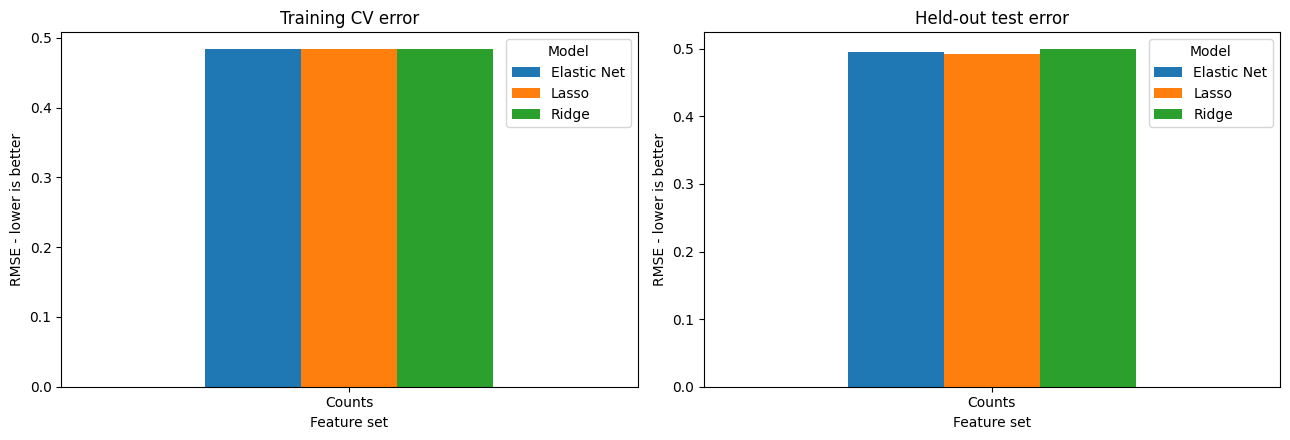


Count-feature test results:


,Feature_set,Model,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.483678,0.499468,0.774054,0.780403,0.614330,0.886583,0.725764,0.01,NaN,6,8.512105,NaN
1,Counts,Lasso,0.483477,0.492897,0.775871,0.779338,0.592478,0.900941,0.714853,0.01,NaN,4,6.891147,NaN
2,Counts,Elastic Net,0.483268,0.495238,0.775696,0.781062,0.603500,0.894546,0.720750,0.01,0.5,6,18.207461,NaN



Training TF-IDF models...
Training TF-IDF / Ridge...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Completed TF-IDF / Ridge: 82.505 seconds, 3,000 non-zero coefficients
Training TF-IDF / Lasso...
Completed TF-IDF / Lasso: 130.551 seconds, 648 non-zero coefficients
Training TF-IDF / Elastic Net...
Completed TF-IDF / Elastic Net: 860.334 seconds, 2,152 non-zero coefficients
Completed feature set TF-IDF: 1073.424 seconds

TF-IDF cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Ridge,0.1944357408,1.0000,NaN,3000,82.505432750,False
1,TF-IDF,Elastic Net,0.1971909230,0.0001,0.1,2152,860.334484375,True
2,TF-IDF,Lasso,0.2217135344,0.0001,NaN,648,130.551372500,True


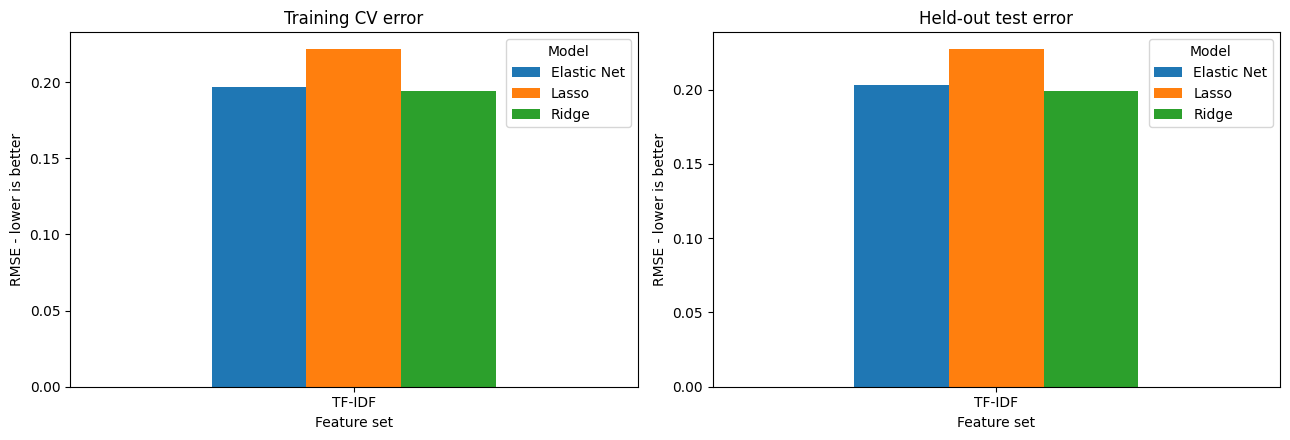


TF-IDF test results:


,Feature_set,Model,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Ridge,0.194436,0.199372,0.995974,0.995238,0.969142,0.977679,0.973392,1.0000,NaN,3000,82.505433,NaN
1,TF-IDF,Lasso,0.221714,0.227186,0.993042,0.991821,0.954933,0.974059,0.964401,0.0001,NaN,648,130.551373,NaN
2,TF-IDF,Elastic Net,0.197191,0.203426,0.995804,0.994672,0.966249,0.977558,0.971871,0.0001,0.1,2152,860.334484,NaN



Available test-score sets:
Counts - Ridge: 16101 predictions, min=-16.877724, max=2.322289
Counts - Lasso: 16101 predictions, min=-12.391170, max=1.924018
Counts - Elastic Net: 16101 predictions, min=-14.380350, max=2.103797
TF-IDF - Ridge: 16101 predictions, min=-0.515445, max=1.461624
TF-IDF - Lasso: 16101 predictions, min=-0.685064, max=1.433190
TF-IDF - Elastic Net: 16101 predictions, min=-0.462983, max=1.385174


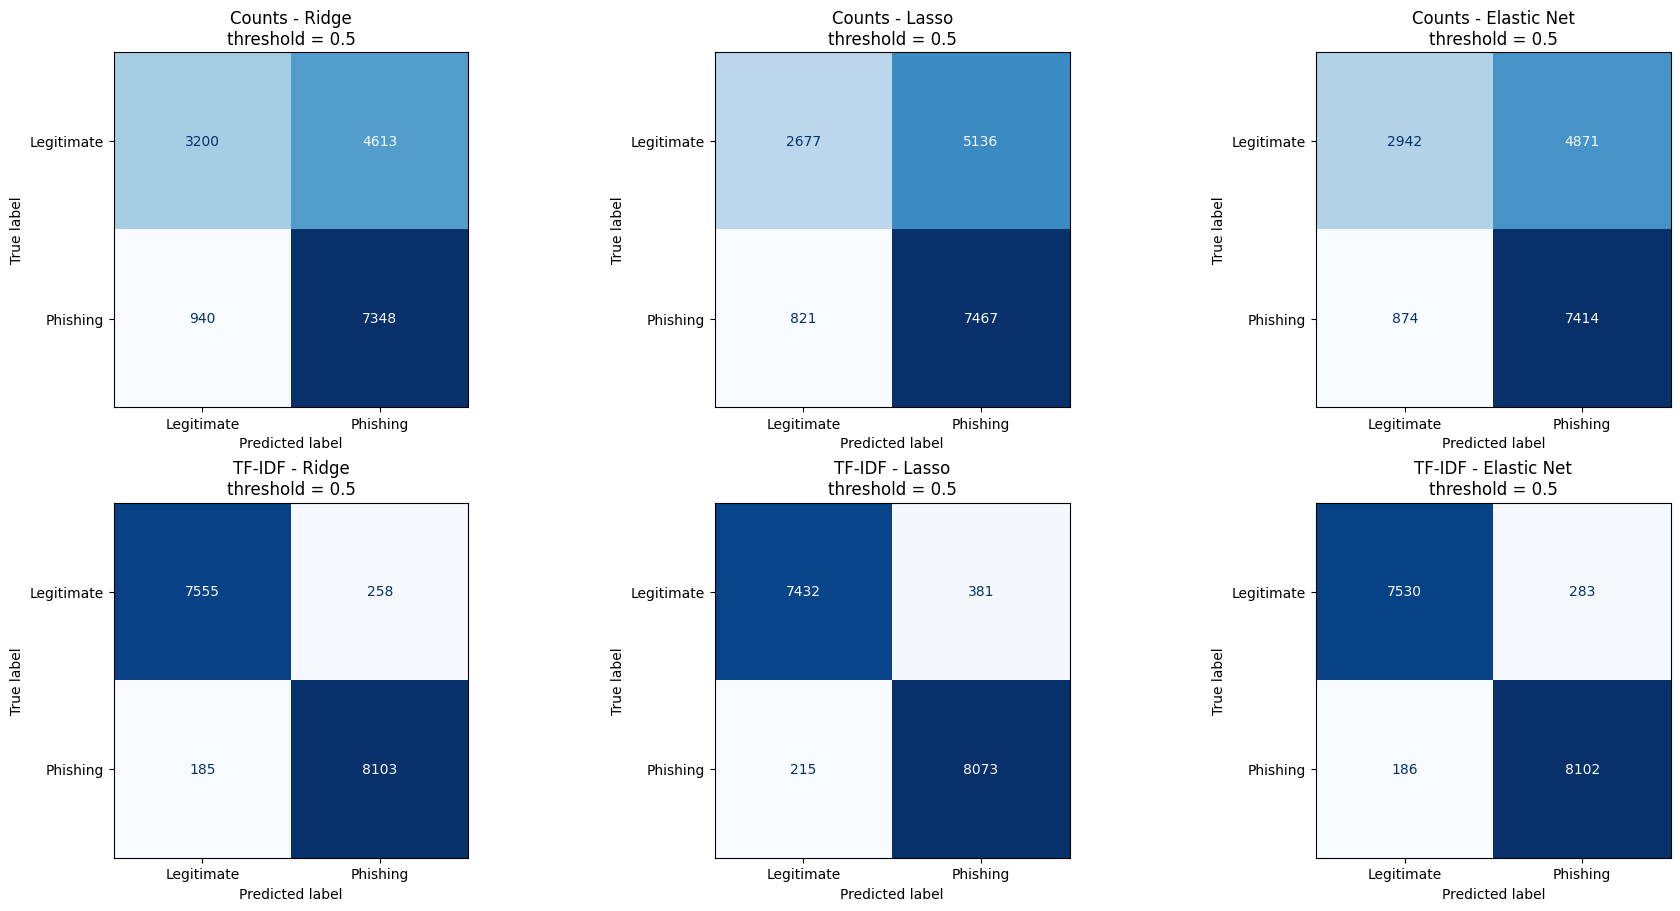


Combined model comparison:


,Feature_set,Model,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.483678,0.499468,0.774054,0.780403,0.614330,0.886583,0.725764,0.0100,NaN,6,8.512105,NaN
1,Counts,Lasso,0.483477,0.492897,0.775871,0.779338,0.592478,0.900941,0.714853,0.0100,NaN,4,6.891147,NaN
2,Counts,Elastic Net,0.483268,0.495238,0.775696,0.781062,0.603500,0.894546,0.720750,0.0100,0.5,6,18.207461,NaN
3,TF-IDF,Ridge,0.194436,0.199372,0.995974,0.995238,0.969142,0.977679,0.973392,1.0000,NaN,3000,82.505433,NaN
4,TF-IDF,Lasso,0.221714,0.227186,0.993042,0.991821,0.954933,0.974059,0.964401,0.0001,NaN,648,130.551373,NaN
5,TF-IDF,Elastic Net,0.197191,0.203426,0.995804,0.994672,0.966249,0.977558,0.971871,0.0001,0.1,2152,860.334484,NaN


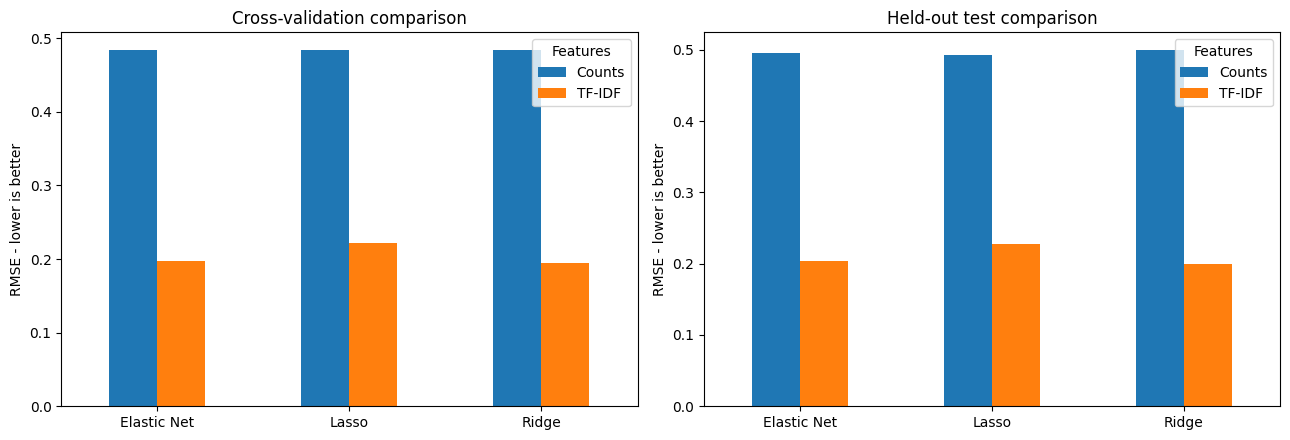


Model fitting time and coefficient sparsity:


,Feature_set,Model,Fit_Time_Seconds,Nonzero_coefficients,Best_alpha,Best_l1_ratio
0,Counts,Lasso,6.891147,4,0.0100,NaN
1,Counts,Ridge,8.512105,6,0.0100,NaN
2,Counts,Elastic Net,18.207461,6,0.0100,0.5
3,TF-IDF,Ridge,82.505433,3000,1.0000,NaN
4,TF-IDF,Lasso,130.551373,648,0.0001,NaN
5,TF-IDF,Elastic Net,860.334484,2152,0.0001,0.1



Total regression experiment execution time: 1161.273 seconds


In [ ]:
# Uses existing df_combined with:
#   text_combined
#   label

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import ConfusionMatrixDisplay


MAX_FEATURES_TFIDF = 3000
THRESHOLD = 0.5
CLASS_NAMES = ["Legitimate", "Phishing"]

experiment_start = time.perf_counter()

# Prepare the corpus
corpus, audit = prepare_count_dataset(df_combined)

train_df, test_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,
    cv_folds=3,
    random_state=42,
)

display(audit["summary"].to_frame("Count"))

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

# Counts feature models
print("\nTraining count-feature models...")

count_searches, count_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("Counts",),
        n_jobs=2,
    )
)

print("\nCount-feature cross-validation results:")

with pd.option_context("display.precision", 10):
    display(count_cv_results)

count_results, count_test_scores = evaluate_comparison(
    searches=count_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nCount-feature test results:")

display(count_results.round(6))

# TF-IDF feature models
print("\nTraining TF-IDF models...")

tfidf_searches, tfidf_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("TF-IDF",),
        max_features=MAX_FEATURES_TFIDF,
        min_df=5,
        n_jobs=2,
    )
)

print("\nTF-IDF cross-validation results:")

with pd.option_context("display.precision", 10):
    display(tfidf_cv_results)

tfidf_results, tfidf_test_scores = evaluate_comparison(
    searches=tfidf_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nTF-IDF test results:")

display(tfidf_results.round(6))

# Combine raw test scores for confusion matrices
test_scores = {
    **count_test_scores,
    **tfidf_test_scores,
}

y_test = test_df["label"].to_numpy()

print("\nAvailable test-score sets:")

for name, scores in test_scores.items():
    scores = np.asarray(scores).ravel()

    print(
        f"{name}: "
        f"{len(scores)} predictions, "
        f"min={scores.min():.6f}, "
        f"max={scores.max():.6f}"
    )

# Confusion matrices: two rows of three plots
if not test_scores:
    raise ValueError(
        "No test scores were returned. "
        "Check the evaluate_comparison() return values."
    )

n_plots = len(test_scores)
n_columns = 3
n_rows = int(np.ceil(n_plots / n_columns))

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

# Flatten the 2D axes grid so it can be used in the loop.
axes = axes.ravel()

for ax, (name, scores) in zip(
    axes,
    test_scores.items(),
):
    scores = np.asarray(scores).ravel()

    if len(scores) != len(y_test):
        raise ValueError(
            f"{name}: {len(scores)} predictions were generated, "
            f"but y_test contains {len(y_test)} labels."
        )

    if not np.isfinite(scores).all():
        raise ValueError(
            f"{name}: predictions contain NaN or infinite values."
        )

    predictions = (
        scores >= THRESHOLD
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(
        f"{name}\nthreshold = {THRESHOLD}"
    )

# Hide unused axes if there are fewer than six model plots.
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()


# Combine all model results
comparison = pd.concat(
    [
        count_results,
        tfidf_results,
    ],
    ignore_index=True,
)

comparison_columns = [
    "Feature_set",
    "Model",
    "CV_RMSE",
    "Test_RMSE",
    "ROC_AUC",
    "Average_precision",
    "Precision",
    "Recall",
    "F1",
    "Best_alpha",
    "Best_l1_ratio",
    "Nonzero_coefficients",
    "Fit_Time_Seconds",
    "Alpha_at_grid_edge",
]

available_columns = [
    column
    for column in comparison_columns
    if column in comparison.columns
]

print("\nCombined model comparison:")

display(
    comparison[
        available_columns
    ].round(6)
)

# Compare cross-validation and held-out test RMSE
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

for ax, metric, title in zip(
    axes,
    ["CV_RMSE", "Test_RMSE"],
    [
        "Cross-validation comparison",
        "Held-out test comparison",
    ],
):
    comparison.pivot(
        index="Model",
        columns="Feature_set",
        values=metric,
    ).plot.bar(
        ax=ax,
        rot=0,
    )

    ax.set_title(title)
    ax.set_ylabel("RMSE - lower is better")
    ax.set_xlabel("")
    ax.legend(title="Features")

fig.tight_layout()
plt.show()

# Display timing and coefficient sparsity
print("\nModel fitting time and coefficient sparsity:")

timing_columns = [
    "Feature_set",
    "Model",
    "Fit_Time_Seconds",
    "Nonzero_coefficients",
    "Best_alpha",
    "Best_l1_ratio",
]

available_timing_columns = [
    column
    for column in timing_columns
    if column in comparison.columns
]

timing_table = (
    comparison[
        available_timing_columns
    ]
    .sort_values("Fit_Time_Seconds")
    .reset_index(drop=True)
)

display(timing_table.round(6))

# Total experiment execution time
total_experiment_time_seconds = (
    time.perf_counter() - experiment_start
)

print(
    "\nTotal regression experiment execution time: "
    f"{total_experiment_time_seconds:.3f} seconds"
)

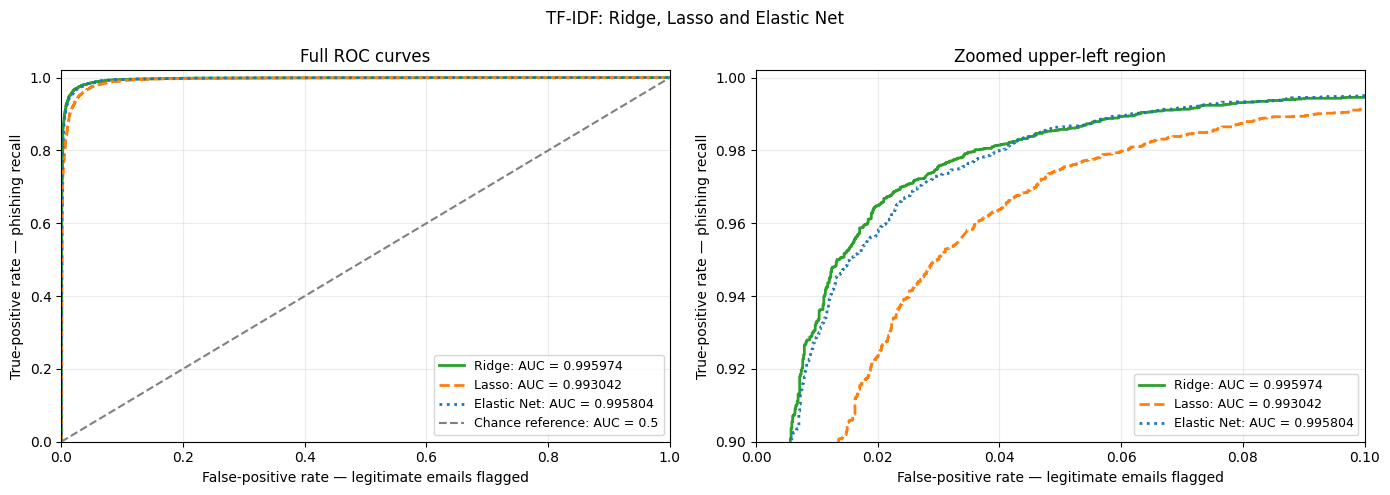

,Feature_set,Model,ROC_AUC
0,TF-IDF,Ridge,0.995974
1,TF-IDF,Elastic Net,0.995804
2,TF-IDF,Lasso,0.993042


In [ ]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


def plot_roc_auc(searches, test, title="Test ROC curves"):
    y_true = test["label"].to_numpy()

    colors = {
        "Ridge": "tab:green",
        "Lasso": "tab:orange",
        "Elastic Net": "tab:blue",
    }

    styles = {
        "Ridge": "-",
        "Lasso": "--",
        "Elastic Net": ":",
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rows = []

    for (feature_set, model_name), search in searches.items():

        # Raw regression scores: do not threshold or clip them.
        scores = search.predict(test)

        fpr, tpr, _ = roc_curve(y_true, scores, pos_label=1)
        auc_value = roc_auc_score(y_true, scores)

        label = f"{model_name}: AUC = {auc_value:.6f}"

        for ax in axes:
            ax.plot(
                fpr,
                tpr,
                label=label,
                color=colors[model_name],
                linestyle=styles[model_name],
                linewidth=2,
            )

        rows.append({
            "Feature_set": feature_set,
            "Model": model_name,
            "ROC_AUC": auc_value,
        })

    # Full ROC graph.
    axes[0].plot(
        [0, 1], [0, 1],
        color="gray",
        linestyle="--",
        label="Chance reference: AUC = 0.5",
    )
    axes[0].set(
        title="Full ROC curves",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )

    # Zoom helps distinguish models with very high AUC.
    axes[1].set(
        title="Zoomed upper-left region",
        xlim=(0, 0.10),
        ylim=(0.90, 1.002),
    )

    for ax in axes:
        ax.set_xlabel("False-positive rate — legitimate emails flagged")
        ax.set_ylabel("True-positive rate — phishing recall")
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right", fontsize=9)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    return (
        pd.DataFrame(rows)
        .sort_values("ROC_AUC", ascending=False)
        .reset_index(drop=True)
    )
tfidf_auc_results = plot_roc_auc(
    searches=tfidf_searches,
    test=test_df,
    title="TF-IDF: Ridge, Lasso and Elastic Net",
)

display(tfidf_auc_results.round(6))

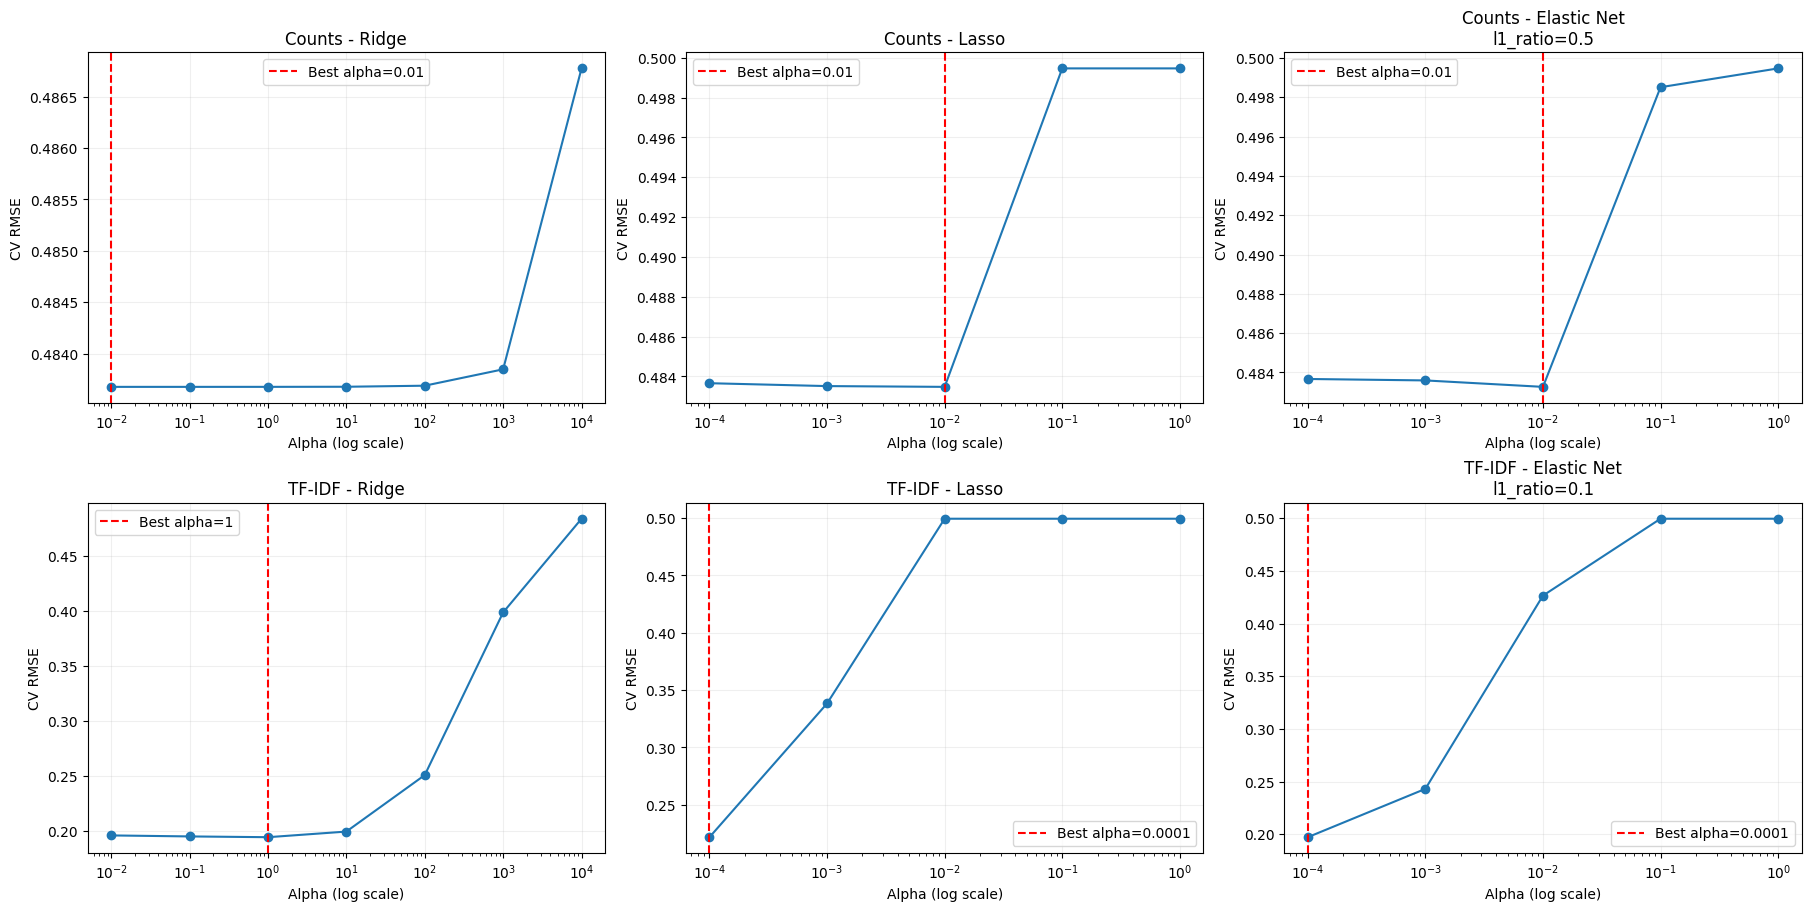

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


all_searches = {
    **count_searches,
    **tfidf_searches,
}

if not all_searches:
    raise ValueError(
        "No fitted searches were found. "
        "Run compare_regression_features() first."
    )

n_plots = len(all_searches)
n_columns = 3
n_rows = math.ceil(n_plots / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

for ax, ((feature_set, model_name), search) in zip(
    axes,
    all_searches.items(),
):
    cv_table = pd.DataFrame(
        search.cv_results_
    )

    title = (
        f"{feature_set} - {model_name}"
    )

    # Elastic Net evaluates multiple l1_ratio values
    # for each alpha. Keep only the selected ratio.
    if model_name == "Elastic Net":
        best_ratio = float(
            search.best_params_[
                "model__l1_ratio"
            ]
        )

        ratio_values = pd.to_numeric(
            cv_table[
                "param_model__l1_ratio"
            ],
            errors="coerce",
        )

        cv_table = cv_table[
            np.isclose(
                ratio_values,
                best_ratio,
                equal_nan=False,
            )
        ].copy()

        title += (
            f"\nl1_ratio={best_ratio:g}"
        )

    cv_table = cv_table.assign(
        alpha=pd.to_numeric(
            cv_table[
                "param_model__alpha"
            ],
            errors="coerce",
        ),
        rmse=np.sqrt(
            -pd.to_numeric(
                cv_table[
                    "mean_test_score"
                ],
                errors="coerce",
            )
        ),
    ).dropna(
        subset=["alpha", "rmse"]
    ).sort_values(
        "alpha"
    )

    if cv_table.empty:
        ax.text(
            0.5,
            0.5,
            "No CV results available",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.set_title(title)
        continue

    ax.semilogx(
        cv_table["alpha"],
        cv_table["rmse"],
        marker="o",
        linewidth=1.5,
    )

    best_alpha = float(
        search.best_params_[
            "model__alpha"
        ]
    )

    ax.axvline(
        best_alpha,
        color="red",
        linestyle="--",
        label=(
            f"Best alpha={best_alpha:.4g}"
        ),
    )

    ax.set_title(title)
    ax.set_xlabel("Alpha (log scale)")
    ax.set_ylabel("CV RMSE")
    ax.grid(alpha=0.2)
    ax.legend()

# Hide unused axes if there are fewer than
# six search results.
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()

#### Observtion from execution 9 Static Count Features (~82k Dataset)

#### Key Takeaways

* **Scale Restores Signal:** With a larger dataset of ~82,000 emails (~16,101 test) elevates ROC AUC to **~0.775** across all linear models, preventing the total model collapse seen on smaller datasets.
* **Severe False Positive Bias:** At the default 0.5 decision threshold, models capture ~89–90% of phishing emails but misclassify **59% to 65% of legitimate emails** as phishing.
* **Ridge is the Top Performer:** Delivers the highest F1 score (**0.7258**), highest precision (**0.6143**), and lowest false positive count in **8.51 seconds**.
* **Feature Pruning:** Lasso eliminated 5 redundant features (retaining **4/9**), while Ridge and Elastic Net retained **6/9**, showing that at least 3 static count features offer no predictive value.

---

#### Performance Summary (Threshold = 0.5)

| Model | Test RMSE | ROC AUC | Precision | Recall | F1 Score | Retained Features | Fit Time (s) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Ridge (Best)** | **0.4995** | **0.7741** | **0.6143** | **0.8866** | **0.7258** | **6 / 9** | **8.51** |
| **Elastic Net** | 0.4952 | 0.7757 | 0.6035 | 0.8945 | 0.7208 | 6 / 9 | 18.21 |
| **Lasso** | 0.4929 | 0.7759 | 0.5925 | 0.9009 | 0.7149 | 4 / 9 | 6.89 |

---

#### Test Set Confusion Matrix Breakdown (16,101 Samples)

* **Ridge:** True Negative: 3,200 | **False Positive: 4,613** | False Negative: 940 | **True Positive: 7,348**
* **Elastic Net:** True Negative: 2,942 | **False Positive: 4,871** | False Negative: 874 | **True Positive: 7,414**
* **Lasso:** True Negative: 2,677 | **False Positive: 5,136** | False Negative: 821 | **True Positive: 7,467**

---

#### Recommendations

1. Try other techniques  which will give us better features and static will not work  as trend with time will change
2. Look into TF-IDF as an approach which we can then generate vectors in larger dimension wqhich can capture these relationships much better
3. **Threshold Tuning:** We sould potentially try changing the treshhold between 0.3 and 0.7 and see what gives the best results to avoid high false positives and false negatives

#### Observation from TFiDF based vector representation of email text and using lineasrt regression with Lasso , Ridger and ElasticNet 


### Executive Summary: Phishing Email Classification Analysis (~82,000 Email Dataset)

#### 1. Key Verdict & Primary Recommendation

**Deploy TF-IDF + Ridge Regression for Production.**

Across all evaluated feature sets and model configurations at a classification threshold of **0.5**, **TF-IDF with Ridge Regression** emerges as the indisputable top performer:
* **Highest Accuracy & F1 Score:** Achieves an **F1 score of 0.973392** and **Precision of 0.969142**, with a test RMSE of **0.199372**.
* **Exceptional Execution Speed:** Fits in **82.51 seconds**, running over **10.4 times faster** than Elastic Net (**860.33 seconds**) while delivering superior classification metrics.
* **Minimal Error Profile:** Produces only **258 False Positives** and **185 False Negatives** out of 16,101 test emails.

Static count features (9 custom features) show improved performance at scale compared to smaller datasets (ROC AUC ~0.775 vs ~0.51 previously), but suffer from an unacceptable **False Positive Rate (~59%–65%)** at threshold 0.5, making them unviable as standalone predictors.

---

#### 2. Complete Performance Comparison Table

*Evaluated on held-out test data (16,101 samples) at threshold = 0.5:*

| Feature Set | Model | CV RMSE | Test RMSE | ROC AUC | Precision | Recall | F1 Score | Non-zero Coefs | Fit Time (s) | Best Alpha | Best L1 Ratio |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Counts** | Ridge | 0.483678 | 0.499468 | 0.774054 | 0.614330 | 0.886583 | 0.725764 | 6 / 9 | 8.51 | 0.0100 | NaN |
| **Counts** | Lasso | 0.483477 | 0.492897 | 0.775871 | 0.592478 | 0.900941 | 0.714853 | 4 / 9 | 6.89 | 0.0100 | NaN |
| **Counts** | Elastic Net | 0.483268 | 0.495238 | 0.775696 | 0.603500 | 0.894546 | 0.720750 | 6 / 9 | 18.21 | 0.0100 | 0.5 |
| **TF-IDF** | **Ridge (Best)** | **0.194436** | **0.199372** | **0.995974** | **0.969142** | **0.977679** | **0.973392** | **3,000** | **82.51** | **1.0000** | **NaN** |
| **TF-IDF** | Lasso | 0.221714 | 0.227186 | 0.993042 | 0.954933 | 0.974059 | 0.964401 | 648 | 130.55 | 0.0001 | NaN |
| **TF-IDF** | Elastic Net | 0.197191 | 0.203426 | 0.995804 | 0.966249 | 0.977558 | 0.971871 | 2,152 | 860.33 | 0.0001 | 0.1 |

---

#### 3. Confusion Matrix Analysis (Threshold = 0.5)

*Total Test Samples = 16,101 (Legitimate = 7,813 | Phishing = 8,288)*

##### TF-IDF Features
* **Ridge Regression (Optimal):**
  * **True Negatives (Legitimate):** 7,555
  * **False Positives (Legitimate flagged as Phishing):** 258
  * **False Negatives (Phishing missed):** 185
  * **True Positives (Phishing caught):** 8,103
* **Elastic Net:**
  * **True Negatives:** 7,530 | **False Positives:** 283 | **False Negatives:** 186 | **True Positives:** 8,102
* **Lasso:**
  * **True Negatives:** 7,432 | **False Positives:** 381 | **False Negatives:** 215 | **True Positives:** 8,073

##### Count Features (9 Static Features)
* **Ridge:** True Negatives: 3,200 | **False Positives: 4,613** | False Negatives: 940 | True Positives: 7,348
* **Elastic Net:** True Negatives: 2,942 | **False Positives: 4,871** | False Negatives: 874 | True Positives: 7,414
* **Lasso:** True Negatives: 2,677 | **False Positives: 5,136** | False Negatives: 821 | True Positives: 7,467

---

#### 4. Regularization Parameters, Sparsity, and Fit Times

1. **L1 Penalty & Feature Selection (Lasso):**
   * **TF-IDF:** Lasso ($\alpha = 0.0001$) aggressively zeroed out **78.4% of features**, reducing the parameter space from 3,000 down to **648 active non-zero coefficients** while maintaining a strong F1 score of **0.964401**.
   * **Counts:** Lasso ($\alpha = 0.01$) pruned 5 features, retaining **4 non-zero coefficients**.
2. **Elastic Net (L1 + L2 Mix):**
   * **TF-IDF:** Optimal `l1_ratio = 0.1` and `alpha = 0.0001` yielded **2,152 non-zero coefficients**.
   * **Counts:** Optimal `l1_ratio = 0.5` and `alpha = 0.01` retained **6 non-zero coefficients**.
3. **Ridge (L2 Smooth Shrinkage):**
   * **TF-IDF:** Optimal `alpha = 1.0` retained all **3,000 features**. L2 regularization prevents overfitting without zeroing weights, achieving the lowest test RMSE (**0.199372**) and fastest TF-IDF training time (**82.51s**).
   * **Counts:** Optimal `alpha = 0.01` retained **6 non-zero coefficients** in **8.51 seconds**.

---

#### 5. Subjective Summary & Recommendations

* **TF-IDF is essential for low False Positive Rates:** Using full text TF-IDF vectorization reduces False Positives from ~4,613 (Counts Ridge) down to **258** (TF-IDF Ridge), representing an **18x reduction in false alarms**.
* **Lasso is ideal for Memory-Constrained Edge Nodes:** If deployment requires a lightweight model, **TF-IDF Lasso** cuts feature memory usage by **78.4%** (648 features vs 3,000) with only a minor performance tradeoff (F1 drops from 0.9734 to 0.9644).
* **Avoid Standalone Count Features:** Although 9 static count features achieve a respectable ROC AUC of ~0.775 on ~82,000 samples, their high false positive rate renders them unusable on their own. It could be merged into TF-IDF sparse matrices as supplementary metadata features rather than used independently.